# Análise ITUB4 — Itaú Unibanco

1. Análise técnica (médias móveis, cruzamentos e Bandas de Bollinger)
2. Rentabilidade x CDI
3. Análise fundamentalista (ROE, P/L, P/VP e Dividend Yield)
4. Contexto macro: inadimplência e juros do Sistema Financeiro Nacional

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from bcb import sgs

pio.templates.default = 'plotly_dark'
sns.set_theme(style='whitegrid')

# Parâmetros da análise (datas fixas = resultados reproduzíveis)
TICKER = 'ITUB4.SA'
INICIO = '2025-08-01'
FIM = '2026-08-01'
APORTE_INICIAL = 4000

ticker = yf.Ticker(TICKER)


def eixo_mensal(fig):
    """Padroniza o eixo X dos gráficos diários em ticks mensais."""
    fig.update_xaxes(dtick='M1', tickformat='%m/%Y')
    return fig

## 1. Dados históricos

In [2]:
df = (
    ticker.history(start=INICIO, end=FIM)
    .drop(columns=['Dividends', 'Stock Splits'])
    .reset_index()
)
df['Date'] = df['Date'].dt.tz_localize(None)

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    250 non-null    datetime64[ns]
 1   Open    250 non-null    float64       
 2   High    250 non-null    float64       
 3   Low     250 non-null    float64       
 4   Close   250 non-null    float64       
 5   Volume  250 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 11.8 KB


,Date,Open,High,Low,Close,Volume
count,250,250.000000,250.000000,250.000000,250.000000,2.500000e+02
mean,2026-01-30 01:32:09.600000,39.218896,39.609844,38.838017,39.206669,2.534149e+07
min,2025-08-01 00:00:00,31.281954,31.583940,30.855623,31.024380,7.190900e+06
25%,2025-10-28 06:00:00,35.243392,35.446820,34.772134,35.108094,1.778592e+07
50%,2026-01-29 12:00:00,39.100907,39.531729,38.815465,39.100903,2.250145e+07
75%,2026-05-04 18:00:00,42.568592,42.809380,42.085655,42.484955,3.253908e+07
max,2026-07-31 00:00:00,48.026688,48.633752,47.586075,48.340012,8.033440e+07
std,NaN,4.265391,4.329230,4.139782,4.239765,1.093056e+07


## 2. Médias móveis

**Médias móveis** suavizam o ruído diário do gráfico e ajudam a revelar a tendência do ativo em uma janela de tempo; são "móveis" porque avançam dia após dia.

- **Média Móvel Simples (SMA)**: média aritmética tradicional. Mais estável, boa para identificar suportes e resistências.
- **Média Móvel Exponencial (EMA)**: média ponderada que dá peso maior aos dias mais recentes, reagindo mais rápido a mudanças de preço.

In [3]:
for janela in (21, 50):
    df[f'SMA_{janela}'] = df['Close'].rolling(janela).mean()
    df[f'EMA_{janela}'] = df['Close'].ewm(span=janela, adjust=False).mean()

**Golden Cross**: a média de curto prazo cruza para cima da de longo prazo, sinalizando tendência de alta.

**Death Cross**: a média de curto prazo cruza para baixo da de longo prazo, sinalizando tendência de baixa.

O sinal só é calculado quando as duas médias existem, evitando um cruzamento falso no dia em que a SMA 50 aparece pela primeira vez.

In [4]:
medias_validas = df[['SMA_21', 'SMA_50']].notna().all(axis=1)
df['Sinal'] = np.where(df['SMA_21'] > df['SMA_50'], 1.0, 0.0)
df.loc[~medias_validas, 'Sinal'] = np.nan
df['Cruzamento'] = df['Sinal'].diff()

cruzamentos = df.loc[df['Cruzamento'].isin([1, -1]), ['Date', 'Close', 'SMA_50', 'Cruzamento']]
cruzamentos['Tipo'] = cruzamentos['Cruzamento'].map({1: 'Golden Cross', -1: 'Death Cross'})
cruzamentos[['Date', 'Close', 'Tipo']]

,Date,Close,Tipo
60,2025-10-24,34.137051,Death Cross
68,2025-11-05,36.038223,Golden Cross
159,2026-03-23,42.249954,Death Cross
183,2026-04-28,43.571819,Golden Cross
195,2026-05-15,39.241047,Death Cross
229,2026-07-03,42.664639,Golden Cross


In [5]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df['Date'], y=df['Close'], name='Preço de Fechamento', opacity=0.5))
fig.add_trace(go.Scatter(x=df['Date'], y=df['SMA_21'], name='SMA 21', line=dict(color='orange', width=2)))
fig.add_trace(go.Scatter(x=df['Date'], y=df['SMA_50'], name='SMA 50', line=dict(color='red', width=2)))
fig.add_trace(go.Scatter(x=df['Date'], y=df['EMA_21'], name='EMA 21', line=dict(dash='dot'), visible='legendonly'))
fig.add_trace(go.Scatter(x=df['Date'], y=df['EMA_50'], name='EMA 50', line=dict(dash='dot'), visible='legendonly'))

estilos = {
    'Golden Cross': dict(symbol='triangle-up', color='green'),
    'Death Cross': dict(symbol='triangle-down', color='white'),
}
for tipo, estilo in estilos.items():
    pontos = cruzamentos[cruzamentos['Tipo'] == tipo]
    fig.add_trace(go.Scatter(x=pontos['Date'], y=pontos['SMA_50'], mode='markers',
                             name=tipo, marker=dict(size=12, **estilo)))

fig.update_layout(title='Tendência e Cruzamentos de Médias Móveis — Itaú',
                  xaxis_title='Período Analisado', yaxis_title='Preço (R$)')
eixo_mensal(fig).show()

No período houve **3 Golden Cross** (11/2025, 04/2026 e 07/2026) e **3 Death Cross**. Apenas o de **11/2025** gerou uma tendência de alta clara e duradoura (até 03/2026); o de 04/2026 foi revertido em menos de 3 semanas. Cruzamentos de médias curtas (21/50) geram bastante ruído neste ativo; médias mais longas (ex.: 50/200) tendem a ser mais confiáveis.

## 3. Variação diária do preço

In [6]:
fig = go.Figure(go.Candlestick(x=df['Date'], open=df['Open'], high=df['High'],
                               low=df['Low'], close=df['Close'], name='Preço'))
fig.update_layout(title='<b>Variação Diária do Preço do Itaú</b>', title_x=0.5,
                  yaxis_title='Preço (R$)', xaxis_rangeslider_visible=False)
eixo_mensal(fig).show()

retorno_periodo = df['Close'].iloc[-1] / df['Close'].iloc[0] - 1
minima, maxima = df['Close'].min(), df['Close'].max()
print(f'Retorno no período: {retorno_periodo:+.2%}')
print(f'Mínima: R$ {minima:.2f} ({df.loc[df["Close"].idxmin(), "Date"]:%d/%m/%Y})')
print(f'Máxima: R$ {maxima:.2f} ({df.loc[df["Close"].idxmax(), "Date"]:%d/%m/%Y})')
print(f'Da mínima à máxima: {maxima / minima - 1:+.2%}')

Retorno no período: +38.00%
Mínima: R$ 31.02 (01/08/2025)
Máxima: R$ 48.34 (11/02/2026)
Da mínima à máxima: +55.81%


**Retorno de +38% no período** (08/2025 a 07/2026). O ativo chegou a **valorizar 55,8%** da mínima (R\$ 31,02 em 01/08/2025) até a máxima (R\$ 48,34 em 11/02/2026), devolvendo depois parte do ganho.

*Os preços do Yahoo Finance são ajustados por proventos, então o retorno já considera dividendos e JCP reinvestidos.*

## 4. Volatilidade — Bandas de Bollinger

As bandas ficam a **2 desvios-padrão** (multiplicador padrão do mercado) da média de 20 períodos. A **largura relativa** das bandas mede objetivamente a volatilidade.

In [7]:
K = 2
JANELA_BB = 20

df['SMA_20'] = df['Close'].rolling(JANELA_BB).mean()
desvio = df['Close'].rolling(JANELA_BB).std()
df['Banda_Superior'] = df['SMA_20'] + K * desvio
df['Banda_Inferior'] = df['SMA_20'] - K * desvio
df['Largura_Bandas'] = (df['Banda_Superior'] - df['Banda_Inferior']) / df['SMA_20'] * 100

In [8]:
banda = dict(color='rgba(150, 150, 150, 0.6)', width=1.5, dash='dot')

fig = go.Figure()
fig.add_trace(go.Candlestick(x=df['Date'], open=df['Open'], high=df['High'],
                             low=df['Low'], close=df['Close'], name='Preço'))
fig.add_trace(go.Scatter(x=df['Date'], y=df['Banda_Superior'], line=banda, name='Banda Superior'))
fig.add_trace(go.Scatter(x=df['Date'], y=df['Banda_Inferior'], line=banda, name='Banda Inferior',
                         fill='tonexty', fillcolor='rgba(150, 150, 150, 0.1)'))
fig.add_trace(go.Scatter(x=df['Date'], y=df['SMA_20'], line=dict(color='gray', width=1), name='SMA 20'))
fig.update_layout(title='Volatilidade: Preço vs Bandas de Bollinger (20 períodos)',
                  xaxis_title='Período Analisado', yaxis_title='Preço (R$)',
                  xaxis_rangeslider_visible=False)
eixo_mensal(fig).show()

largura = df['Largura_Bandas'].dropna()
print(f'Largura das bandas — início: {largura.iloc[0]:.1f}% | fim: {largura.iloc[-1]:.1f}% | '
      f'média: {largura.mean():.1f}% | máxima: {largura.max():.1f}% ({df.loc[largura.idxmax(), "Date"]:%m/%Y})')

Largura das bandas — início: 10.4% | fim: 5.7% | média: 11.1% | máxima: 27.4% (02/2026)


A largura das bandas teve média de **11,1%** e pico de **27,4% em 02/2026**, justamente na alta acelerada seguida de correção. No fim do período (5,7%) a largura está **abaixo** da inicial (10,4%): a volatilidade não aumentou de forma estrutural, ela se **concentrou no 1º trimestre de 2026**.

## 5. Simulação: aporte de R$ 4.000

In [9]:
df['Retorno_Diario'] = df['Close'].pct_change().fillna(0)
df['Capital'] = APORTE_INICIAL * (1 + df['Retorno_Diario']).cumprod()

fig = go.Figure()
fig.add_trace(go.Scatter(x=df['Date'], y=df['Capital'], name='Capital Acumulado',
                         line=dict(color='#00cc96', width=2),
                         fill='tozeroy', fillcolor='rgba(0, 204, 150, 0.1)'))
fig.add_hline(y=APORTE_INICIAL, line=dict(color='gray', width=1.5, dash='dash'),
              annotation_text=f'Aporte inicial R$ {APORTE_INICIAL:,.0f}')
fig.update_layout(title=f'Evolução de R$ {APORTE_INICIAL:,.0f} investidos em {df["Date"].iloc[0]:%m/%Y}',
                  xaxis_title='Data', yaxis_title='Capital (R$)')
eixo_mensal(fig).show()

pico = df.loc[df['Capital'].idxmax()]
final = df['Capital'].iloc[-1]
print(f'Pico:  R$ {pico["Capital"]:,.2f} ({pico["Capital"] / APORTE_INICIAL - 1:+.1%}) em {pico["Date"]:%d/%m/%Y}')
print(f'Final: R$ {final:,.2f} ({final / APORTE_INICIAL - 1:+.1%})')

Pico:  R$ 6,232.52 (+55.8%) em 11/02/2026
Final: R$ 5,520.09 (+38.0%)


Quem investisse **R\$ 4.000 em agosto de 2025** e vendesse no pico (11/02/2026) teria **R\$ 6.232,52 (+55,8%)**. Mantendo até o fim do período, o capital final seria de **R\$ 5.520,09 (+38,0%)**.

## 6. Itaú (renda variável) x CDI (renda fixa)

A série 12 do SGS/Bacen traz a taxa diária do CDI em % ao dia. As duas curvas são normalizadas em **base 100** na mesma data inicial.

In [10]:
cdi = sgs.get({'CDI': 12}, start=INICIO, end=FIM)
cdi['CDI_Acumulado'] = (1 + cdi['CDI'] / 100).cumprod()

comparativo = (
    df[['Date', 'Close']]
    .merge(cdi[['CDI_Acumulado']], left_on='Date', right_index=True, how='left')
    .ffill()
    .dropna()
)
comparativo['Itau'] = comparativo['Close'] / comparativo['Close'].iloc[0] * 100
comparativo['CDI'] = comparativo['CDI_Acumulado'] / comparativo['CDI_Acumulado'].iloc[0] * 100

In [11]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=comparativo['Date'], y=comparativo['Itau'], name='Itaú', line=dict(color='#FFA500', width=2)))
fig.add_trace(go.Scatter(x=comparativo['Date'], y=comparativo['CDI'], name='CDI', line=dict(color='#00FF00', width=2)))
fig.update_layout(title='Desempenho Acumulado (Base 100): Itaú vs CDI',
                  xaxis_title='Período Analisado', yaxis_title='Base 100',
                  width=900, height=500)
eixo_mensal(fig).show()

final_itau, final_cdi = comparativo['Itau'].iloc[-1], comparativo['CDI'].iloc[-1]
print(f'Itaú: {final_itau:.2f} (máx. {comparativo["Itau"].max():.2f}) | CDI: {final_cdi:.2f}')
print('Itaú rendeu MAIS que o CDI' if final_itau > final_cdi else 'Itaú rendeu MENOS que o CDI')

Itaú: 138.00 (máx. 155.81) | CDI: 114.65
Itaú rendeu MAIS que o CDI


Partindo de 100, o **Itaú terminou em 138,00** (chegando a 155,81) contra **114,65 do CDI**.

**Conclusão**: no período, o Itaú **superou o CDI em cerca de 23 pontos**, porém com volatilidade muito maior — o risco típico da renda variável frente à renda fixa.

## 7. Análise fundamentalista

- **ROE**: rentabilidade do banco sobre o patrimônio líquido (aqui sobre o PL **médio** do ano).
- **P/L e P/VP**: indicam se a ação está cara ou barata em relação ao lucro e ao patrimônio.
- **Dividend Yield**: retorno em dinheiro pago aos acionistas (dividendos + JCP).

In [12]:
dre = ticker.income_stmt
patrimonio = ticker.balance_sheet.loc['Stockholders Equity']

lucro_liquido = dre.loc['Net Income'].iloc[0]
patrimonio_atual = patrimonio.iloc[0]
patrimonio_medio = patrimonio.iloc[:2].mean()
roe = lucro_liquido / patrimonio_medio * 100
data_balanco = dre.columns[0]

info = ticker.info
valor_mercado = info.get('marketCap') or info['currentPrice'] * info['sharesOutstanding']
pl = valor_mercado / lucro_liquido
pvp = valor_mercado / patrimonio_atual

print(f'Balanço de referência: {data_balanco:%d/%m/%Y}')
print(f'Lucro líquido:      R$ {lucro_liquido / 1e9:,.2f} bi')
print(f'Patrimônio líquido: R$ {patrimonio_atual / 1e9:,.2f} bi (médio: R$ {patrimonio_medio / 1e9:,.2f} bi)')
print(f'Valor de mercado:   R$ {valor_mercado / 1e9:,.2f} bi')
print(f'ROE: {roe:.2f}% | P/L: {pl:.2f} | P/VP: {pvp:.2f}')

Balanço de referência: 31/12/2025
Lucro líquido:      R$ 44.86 bi
Patrimônio líquido: R$ 204.50 bi (médio: R$ 207.80 bi)
Valor de mercado:   R$ 446.72 bi
ROE: 21.59% | P/L: 9.96 | P/VP: 2.18


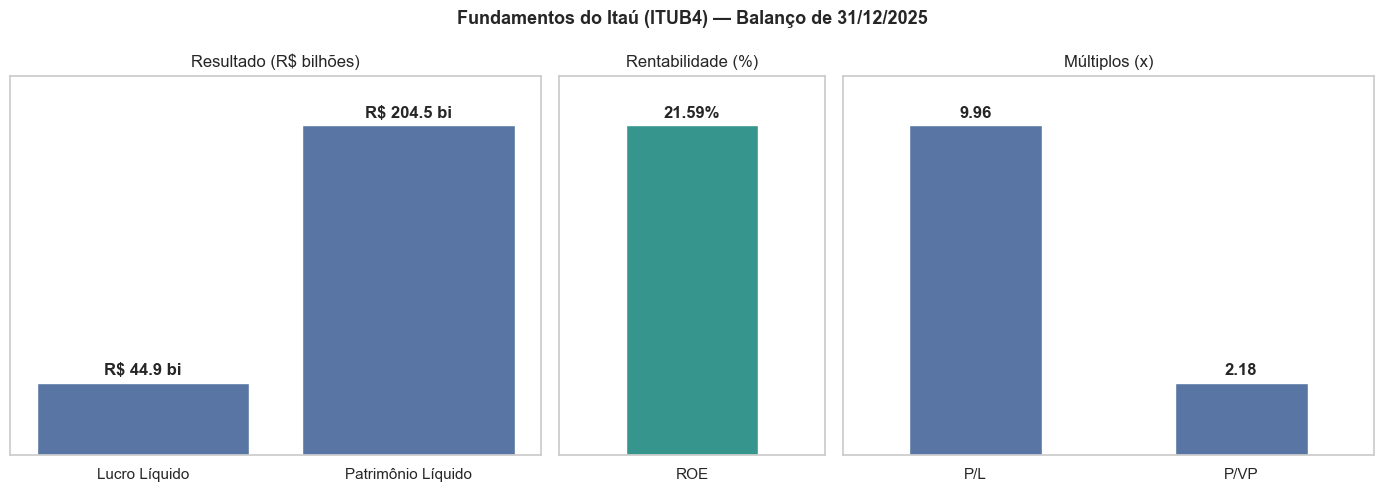

In [13]:
fig, (ax_valores, ax_roe, ax_multiplos) = plt.subplots(1, 3, figsize=(14, 5),
                                                       gridspec_kw={'width_ratios': [2, 1, 2]})

sns.barplot(x=['Lucro Líquido', 'Patrimônio Líquido'], y=[lucro_liquido / 1e9, patrimonio_atual / 1e9], ax=ax_valores)
ax_valores.bar_label(ax_valores.containers[0], fmt='R$ %.1f bi', padding=3, fontweight='bold')
ax_valores.set_title('Resultado (R$ bilhões)')

sns.barplot(x=['ROE'], y=[roe], ax=ax_roe, color='#26A69A', width=0.5)
ax_roe.bar_label(ax_roe.containers[0], fmt='%.2f%%', padding=3, fontweight='bold')
ax_roe.set_title('Rentabilidade (%)')

sns.barplot(x=['P/L', 'P/VP'], y=[pl, pvp], ax=ax_multiplos, width=0.5)
ax_multiplos.bar_label(ax_multiplos.containers[0], fmt='%.2f', padding=3, fontweight='bold')
ax_multiplos.set_title('Múltiplos (x)')

for ax in (ax_valores, ax_roe, ax_multiplos):
    ax.set_yticks([])
    ax.margins(y=0.15)

fig.suptitle(f'Fundamentos do Itaú (ITUB4) — Balanço de {data_balanco:%d/%m/%Y}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

- **ROE de ~21,6%**: forte e alinhado aos maiores bancos privados do país, com lucro líquido de R\$ 44,9 bi.
- **P/L ~10**: o mercado paga cerca de 10 anos de lucro pela ação — nem caro, nem barato.
- **P/VP ~2,2**: bancos com ROE acima de 20% costumam negociar com ágio sobre o patrimônio (P/VP = P/L × ROE).

**Conclusão**: os múltiplos não indicam sub nem sobrevalorização; estão coerentes com a rentabilidade apresentada.

*P/L e P/VP usam o valor de mercado do momento da execução, então variam a cada execução.*

### Dividend Yield histórico

Calculado com o preço de fechamento **não ajustado** (`auto_adjust=False`): usar o preço ajustado por proventos reduziria artificialmente os preços antigos e inflaria o DY.

In [14]:
ANOS = range(2021, 2026)

precos = ticker.history(start='2021-01-01', end='2026-01-01', auto_adjust=False)['Close']
dividendos = ticker.dividends
precos.index = precos.index.tz_localize(None)
dividendos.index = dividendos.index.tz_localize(None)

dy = pd.DataFrame({
    'Dividendos': dividendos.groupby(dividendos.index.year).sum().reindex(ANOS, fill_value=0),
    'Preco_Fim_Ano': precos.groupby(precos.index.year).last().reindex(ANOS),
})
dy['Dividend_Yield'] = dy['Dividendos'] / dy['Preco_Fim_Ano'] * 100
dy.rename_axis('Ano')

$ITUB4.SA: possibly delisted; no price data found  (1d 1927-12-02 -> 2026-11-07)


,Dividendos,Preco_Fim_Ano,Dividend_Yield
Ano,,,
2021,0.800261,18.490732,4.327903
2022,0.898622,22.065313,4.072555
2023,1.109125,29.982347,3.699260
2024,2.129977,27.122683,7.853121
2025,4.449317,39.230000,11.341619


In [15]:
fig = go.Figure(go.Scatter(x=dy.index, y=dy['Dividend_Yield'], mode='lines+markers+text',
                           text=dy['Dividend_Yield'].map('{:.2f}%'.format), textposition='top center',
                           line=dict(color='#26A69A', width=2)))
fig.update_layout(title='Evolução do Dividend Yield do Itaú', xaxis_title='Ano',
                  yaxis_title='Dividend Yield (%)', width=1000, height=500)
fig.update_xaxes(dtick=1)
fig.show()

Entre 2021 e 2023 o DY caiu levemente (4,3% → 3,7%), enquanto o preço subia. A partir de 2024 há um salto expressivo: **7,9% em 2024 e 11,3% em 2025**, quase triplicando em dois anos, reflexo do aumento dos proventos distribuídos (os dividendos por ação foram de R\$ 1,11 em 2023 para R\$ 4,45 em 2025).

## 8. Contexto macro: crédito no Sistema Financeiro Nacional

Séries do SGS/Bacen — são indicadores do **sistema financeiro como um todo**, não da carteira do Itaú:

| Código | Série |
|---|---|
| 21084 | Inadimplência da carteira de crédito — Pessoas físicas |
| 21083 | Inadimplência da carteira de crédito — Pessoas jurídicas |
| 20716 | Taxa média de juros das operações de crédito — Pessoas físicas |
| 29034 | Comprometimento de renda das famílias com o serviço da dívida (com ajuste sazonal) |

In [16]:
SERIES_BCB = {
    'Inadimplencia_PF': 21084,
    'Inadimplencia_PJ': 21083,
    'Juros_PF': 20716,
    'Comprometimento_Renda': 29034,
}
macro = sgs.get(SERIES_BCB, start='2011-03-01')
macro.index = macro.index.to_period('M')

preco_mensal = ticker.history(start='2011-01-01')['Close'].resample('ME').last()
preco_mensal.index = preco_mensal.index.tz_localize(None).to_period('M')

df_macro = macro.join(preco_mensal.rename('Preco_Itau'), how='inner').dropna()
df_macro.tail()

,Inadimplencia_PF,Inadimplencia_PJ,Juros_PF,Comprometimento_Renda,Preco_Itau
Date,,,,,
2026-04,5.51,3.15,38.93,28.38,42.672726
2026-05,5.63,3.25,38.56,28.47,39.577114
2026-06,5.43,3.18,38.34,28.68,42.087471
2026-07,5.80,3.32,37.46,28.83,42.814365
2026-08,6.04,3.36,38.17,28.99,39.467045


A correlação é feita sobre **variações mensais** (retorno da ação e variação em p.p. dos indicadores). Correlacionar níveis de séries com tendência gera correlações espúrias.

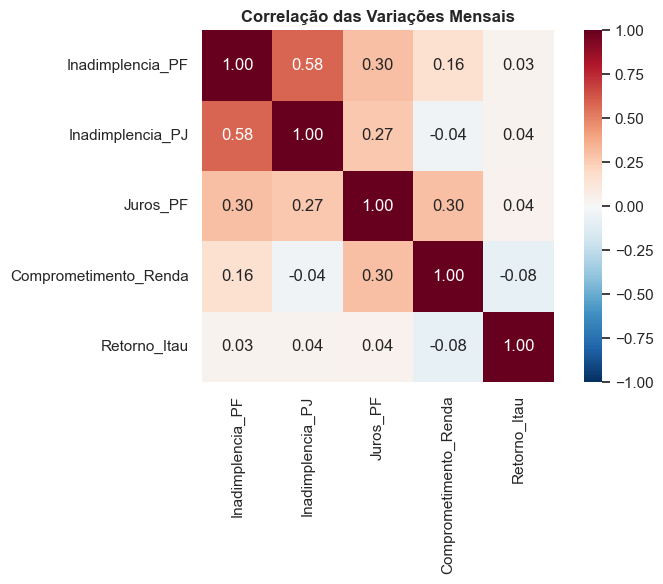

In [17]:
variacoes = df_macro.drop(columns='Preco_Itau').diff()
variacoes['Retorno_Itau'] = df_macro['Preco_Itau'].pct_change()
matriz_correlacao = variacoes.dropna().corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Correlação das Variações Mensais', fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
datas = df_macro.index.to_timestamp()

fig = make_subplots(specs=[[{'secondary_y': True}]])
fig.add_trace(go.Scatter(x=datas, y=df_macro['Preco_Itau'], name='Preço de Fechamento Mensal'), secondary_y=False)
fig.add_trace(go.Scatter(x=datas, y=df_macro['Juros_PF'], name='Taxa de Juros PF'), secondary_y=True)
fig.update_layout(title='Preço Mensal do Itaú vs Taxa de Juros PF', xaxis_title='Período Analisado')
fig.update_yaxes(title_text='Preço (R$)', secondary_y=False)
fig.update_yaxes(title_text='Juros PF (% a.a.)', secondary_y=True)
fig.update_xaxes(tickformat='%Y')
fig.show()

Entre 03/2011 e 08/2026, as correlações entre o **retorno mensal do Itaú** e as variações dos indicadores de crédito são **praticamente nulas** (|r| < 0,1): no curto prazo, a ação não acompanha esses indicadores mês a mês.

Se a correlação fosse feita sobre os **níveis**, o comprometimento de renda apareceria com r ≈ 0,63 contra o preço — uma **correlação espúria**, causada apenas por as duas séries terem tendência de alta ao longo do tempo.